# 03 · SOM cluster figures (Figures 6, 7, 8, 9)

Code for: El Farchouni, A., et al. *Groundwater Recharge Mechanisms in the Haouz-Mejjate Aquifer (Morocco): Insights from Environmental Tracers and Self-Organizing Maps.* Groundwater for Sustainable Development (under review).

**What this notebook does**

Draws the figures that present the four SOM clusters, using the cluster names of the article (C1 Na-Cl enriched, C2 transitional, C3 Ca-HCO₃ dominated, C4 Mg-SO₄ enriched). No training or clustering is repeated: clusters are read from the output of `02_HCA_clustering.ipynb`.

| Figure | Content |
|---|---|
| **Figure 6** | Clustered SOM map (8 × 9 hexagonal grid), samples as white circles |
| **Figure 7** | HCA dendrogram of the 406 samples (Ward linkage, phenon line at distance 16) and median Stiff diagram of each cluster; the panels are assembled in the article |
| **Figure 8** | Piper diagram colored by SOM cluster, marker by water type (WQChartPy) |
| **Figure 9** | Gibbs diagrams colored by SOM cluster (adapted WQChartPy module, `scripts/gibbs_som1.py`) |

| | |
|---|---|
| **Inputs** | `outputs/intermediate/data_final_with_clusters.xlsx`, `som_model_final.p` |
| **Figures** | `outputs/figures/Figure6_clustered_SOM`, `Figure7_panels/` (dendrogram + 4 Stiff diagrams), `Figure8_Piper_SOM`, `Figure9_Gibbs_SOM` |
| **Next notebook** | `04_isotopes/01_isotope_dataset.ipynb` |

### <font color='orange'> **1) Packages, settings and paths** </font>

In [1]:
# ── Core ──────────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
import pickle, sys, warnings
from pathlib import Path

# ── SOM ───────────────────────────────────────────────────────────────
from minisom import MiniSom

# ── Clustering ───────────────────────────────────────────────────────
from scipy.cluster.hierarchy import linkage, fcluster
import scipy.cluster.hierarchy as sch

# ── Plotting helpers ─────────────────────────────────────────────────
from matplotlib.patches import RegularPolygon, Patch
from matplotlib.collections import PatchCollection
from matplotlib.lines import Line2D

# ── WQChartPy (Piper, Stiff) and the adapted Gibbs module in scripts/ ─
from wqchartpy import triangle_piper, stiff

# ── Settings ─────────────────────────────────────────────────────────
warnings.filterwarnings("ignore", category=UserWarning)
plt.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "font.size": 13,
    "axes.labelsize": 15,
    "axes.titlesize": 16,
    "axes.labelweight": "bold",
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "legend.title_fontsize": 13,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "black",
    "axes.grid": True,
    "grid.alpha": 0.3,
    "savefig.bbox": "tight",
    "savefig.transparent": False,
})

SEED = 42
np.random.seed(SEED)

# ── Paths (built from the repository root, so they work on any computer) ──
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "data").is_dir() and (p / "notebooks").is_dir())
DIR_INTERMED = ROOT / "outputs" / "intermediate"
DIR_FIGURES  = ROOT / "outputs" / "figures"
DIR_FIG7     = DIR_FIGURES / "Figure7_panels"
DIR_FIG7.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(ROOT / "scripts"))
import gibbs_som1 as gibbs
print(f"Gibbs module : {Path(gibbs.__file__).relative_to(ROOT)}")
print(f"matplotlib {matplotlib.__version__} | pandas {pd.__version__} | numpy {np.__version__}")

C:\Users\Admin\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


Gibbs module : scripts\gibbs_som1.py
matplotlib 3.7.2 | pandas 2.2.3 | numpy 1.26.4


### <font color='orange'> **2) Load the clustered data and the SOM** </font>

In [2]:
# ── Load final dataset with clusters ─────────────────────────────────
df = pd.read_excel(DIR_INTERMED / "data_final_with_clusters.xlsx")

# ── Column groups ────────────────────────────────────────────────────
MAJOR_IONS  = ["Ca (mg/L)", "Mg (mg/L)", "Na (mg/L)", "K (mg/L)",
               "HCO3 (mg/L)", "Cl (mg/L)", "SO4 (mg/L)"]
IONS_MEQ    = [c.replace("(mg/L)", "(meq/L)") for c in MAJOR_IONS]
IONS_REL    = [c.replace("(mg/L)", "(%)") for c in MAJOR_IONS]
IONS_SCALED = [c.replace("(mg/L)", "(scaled)") for c in MAJOR_IONS]
ION_LABELS  = [c.replace(" (mg/L)", "") for c in MAJOR_IONS]

# ── Load trained SOM model ──────────────────────────────────────────
with open(DIR_INTERMED / "som_model_final.p", "rb") as f:
    som = pickle.load(f)

weights = som.get_weights()
ROWS, COLS = weights.shape[0], weights.shape[1]
data_som = df[IONS_SCALED].values

# ── Cluster colors (consistent across all figures) ──────────────────
K_FINAL = df["Cluster"].nunique()
CLUSTER_COLORS = {1: "#E74C3C", 2: "#3498DB", 3: "#2ECC71", 4: "#F39C12", 5: "#9B59B6"}

# ── Neuron cluster map (same clustering as 02_HCA_clustering.ipynb) ─
codebook = weights.reshape(-1, weights.shape[2])
Z = linkage(codebook, method="average", metric="euclidean")
neuron_labels = fcluster(Z, t=K_FINAL, criterion="maxclust")
neuron_cluster_map = neuron_labels.reshape(ROWS, COLS)

# ── Summary ─────────────────────────────────────────────────────────
print(f"Dataset    : {df.shape[0]} samples × {df.shape[1]} columns")
print(f"SOM grid   : {ROWS}×{COLS} = {ROWS*COLS} neurons (hexagonal)")
print(f"Clusters   : {K_FINAL}")
print(f"\nSamples per cluster:")
for k in range(1, K_FINAL + 1):
    print(f"  Cluster {k}: {(df['Cluster']==k).sum()} samples")

Dataset    : 406 samples × 38 columns
SOM grid   : 8×9 = 72 neurons (hexagonal)
Clusters   : 4

Samples per cluster:
  Cluster 1: 41 samples
  Cluster 2: 128 samples
  Cluster 3: 162 samples
  Cluster 4: 75 samples


### <font color='orange'> **3) Cluster names used in the article** </font>

In [3]:
# ── Cluster labels: hydrochemical-facies names used in the manuscript ─
CLUSTER_LABELS = {
    1: "Na-Cl enriched",
    2: "Transitional",
    3: "Ca-HCO3 dominated",
    4: "Mg-SO4 enriched",
}

# Summary table
df_dominance = pd.DataFrame({
    "Cluster": [f"C{k}" for k in range(1, K_FINAL + 1)],
    "N samples": [(df["Cluster"]==k).sum() for k in range(1, K_FINAL + 1)],
    "Label": [CLUSTER_LABELS[k] for k in range(1, K_FINAL + 1)],
    "Color": [CLUSTER_COLORS[k] for k in range(1, K_FINAL + 1)],
})
display(df_dominance)
print(f"\nCLUSTER_LABELS = {CLUSTER_LABELS}")

,Cluster,N samples,Label,Color
0,C1,41,Na-Cl enriched,#E74C3C
1,C2,128,Transitional,#3498DB
2,C3,162,Ca-HCO3 dominated,#2ECC71
3,C4,75,Mg-SO4 enriched,#F39C12



CLUSTER_LABELS = {1: 'Na-Cl enriched', 2: 'Transitional', 3: 'Ca-HCO3 dominated', 4: 'Mg-SO4 enriched'}


### <font color='orange'> **4) Figure 8: Piper diagram colored by SOM cluster** </font>

> Water types are labelled as in the article legend (Groundwater (Wells), Lake; tributaries merged with streams).

In [4]:
# ── Prepare the WQChartPy format DataFrame ───────────────────────────

# ── Cluster colors (same as the previous notebooks) ──────────────────
cluster_color_map = {
    1: "#E74C3C",   # red
    2: "#3498DB",   # blue
    3: "#2ECC71",   # green
    4: "#F39C12",   # orange
}

# ── Marker by water Type ─────────────────────────────────────────────
type_marker_map = {
    "Groundwater":     "o",
    "Spring":          "^",
    "Stream":          "*",
    "Snow":            "D",
    "Rain":            "v",
    "Dam":             "X",
    "Lac":             "P",
    "Irrigation":      "s",
    "Canal(Zaraba)":   "h",
}

# ── Rename Types ─────────────────────────────────────────────────────
df["Type"] = df["Type"].replace({"Tributary": "Stream", "Zaraba": "Canal(Zaraba)"})

# ── Build the format DataFrame ───────────────────────────────────────
format_df = pd.DataFrame()

format_df["Sample"] = df["SampleID"]
format_df["Label"]  = "C" + df["Cluster"].astype(str)

# Color by cluster
format_df["Color"]  = df["Cluster"].map(cluster_color_map)

# Marker by Type
format_df["Marker"] = df["Type"].map(type_marker_map).fillna("o")

format_df["Size"]   = 30
format_df["Alpha"]  = 0.7

# ── Ion columns (bare names, mg/L) ──────────────────────────────────
format_df["Ca"]   = df["Ca (mg/L)"].values
format_df["Mg"]   = df["Mg (mg/L)"].values
format_df["Na"]   = df["Na (mg/L)"].values
format_df["K"]    = df["K (mg/L)"].values
format_df["HCO3"] = df["HCO3 (mg/L)"].values
format_df["Cl"]   = df["Cl (mg/L)"].values
format_df["SO4"]  = df["SO4 (mg/L)"].values
format_df["CO3"]  = 0  # not measured, set to 0

# ── Clean index (mandatory for WQChartPy) ────────────────────────────
format_df.reset_index(drop=True, inplace=True)

print(f"Format DataFrame: {format_df.shape}")
print(f"Labels: {format_df['Label'].unique()}")
print(f"Colors: {format_df['Color'].unique()}")
print(f"Markers: {format_df['Marker'].unique()}")
print(f"\nTypes: {df['Type'].value_counts().to_dict()}")
display(format_df.head())

Format DataFrame: (406, 14)
Labels: ['C2' 'C3' 'C4' 'C1']
Colors: ['#3498DB' '#2ECC71' '#F39C12' '#E74C3C']
Markers: ['P' '^' '*' 'o' 'X' 'v' 's' 'D']

Types: {'Groundwater': 305, 'Spring': 49, 'Stream': 42, 'Snow': 3, 'Dam': 2, 'Rain': 2, 'Irrigation': 2, 'Lac': 1}


,Sample,Label,Color,Marker,Size,Alpha,Ca,Mg,Na,K,HCO3,Cl,SO4,CO3
0,S5,C2,#3498DB,P,30,0.7,26.4,2.88,75.0,1.0,274.5,14.20,3.460,0
1,S6,C3,#2ECC71,^,30,0.7,48.0,4.80,5.0,5.0,164.7,3.55,3.249,0
2,S7,C3,#2ECC71,^,30,0.7,140.8,4.80,10.0,10.0,427.0,7.10,27.690,0
3,S8,C3,#2ECC71,^,30,0.7,51.2,7.68,5.0,2.0,170.8,7.10,12.520,0
4,S9,C3,#2ECC71,^,30,0.7,88.0,12.96,10.0,5.0,262.3,10.65,13.580,0


Trilinear Piper plot created. Saving it to C:\Users\Admin\OneDrive - Université Mohammed VI Polytechnique\Bureau\Article_Hydrochemistry&Isotopes\haouz-mejjate-recharge-som-emma\notebooks\03_PCA_SOM_HCA 



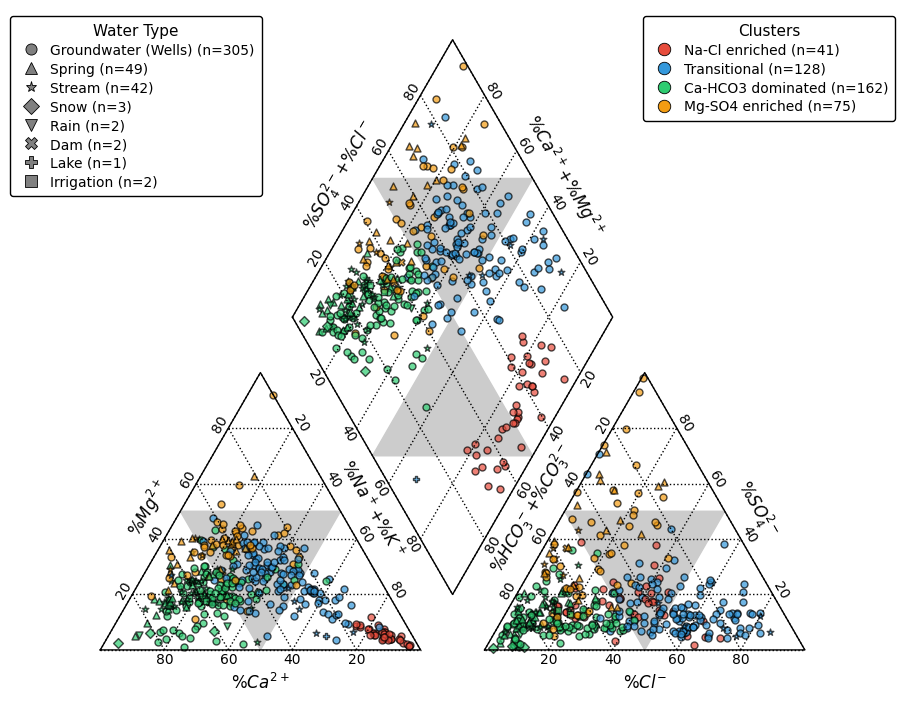

Saved: Figure8_Piper_SOM


In [5]:
# ── Figure 8: Piper diagram, compact corner legends ──────────────────

# ── Labels for the Piper data ────────────────────────────────────────
format_df2 = format_df.copy()
format_df2["Label"] = df["Cluster"].map(CLUSTER_LABELS)
format_df2["Size"] = 25
format_df2.reset_index(drop=True, inplace=True)

piper_figname3 = str(DIR_FIGURES / "Figure8_Piper_SOM")

# Plot Piper (single call)
triangle_piper.plot(
    format_df2,
    unit="mg/L",
    figname=piper_figname3,
    figformat="png",
)

fig = plt.gcf()
ax = fig.get_axes()[0]

# Remove WQChartPy's default legend
old_legend = ax.get_legend()
if old_legend:
    old_legend.remove()

# ── Legend handles (compact) ─────────────────────────────────────────
cluster_handles = [
    Line2D([0], [0], marker="o", color=CLUSTER_COLORS[k], linestyle="None",
           markersize=9, markeredgecolor="black", markeredgewidth=0.6,
           label=f"{CLUSTER_LABELS[k]} (n={(df['Cluster']==k).sum()})")
    for k in range(1, K_FINAL + 1)
]

# Display names for the legend
type_display = {"Groundwater": "Groundwater (Wells)", "Lac": "Lake"}

type_handles = [
    Line2D([0], [0], marker=m, color="gray", linestyle="None",
           markersize=8, markeredgecolor="black", markeredgewidth=0.6,
           label=f"{type_display.get(t, t)} (n={(df['Type']==t).sum()})")
    for t, m in type_marker_map.items() if t in df["Type"].values
]

# ── Compact legends in the top corners (clear of the diamond) ────────
leg1 = ax.legend(handles=type_handles, loc="upper left",
                 bbox_to_anchor=(-0.08, 1.0), fontsize=10,
                 frameon=True, framealpha=1, edgecolor="black",
                 title="Water Type", title_fontsize=11,
                 labelspacing=0.35, handletextpad=0.4, borderpad=0.5)
ax.add_artist(leg1)

leg2 = ax.legend(handles=cluster_handles, loc="upper right",
                 bbox_to_anchor=(1.08, 1.0), fontsize=10,
                 frameon=True, framealpha=1, edgecolor="black",
                 title="Clusters", title_fontsize=11,
                 labelspacing=0.35, handletextpad=0.4, borderpad=0.5)

fig.savefig(piper_figname3 + ".png", dpi=800, bbox_inches="tight",
            bbox_extra_artists=(leg1, leg2))
plt.show()

print("Saved: Figure8_Piper_SOM")

### <font color='orange'> **5) Figure 6: clustered SOM map** </font>

> Drawn after the Piper diagram on purpose: WQChartPy sets global font sizes when it draws, and the article figure was produced in that state.

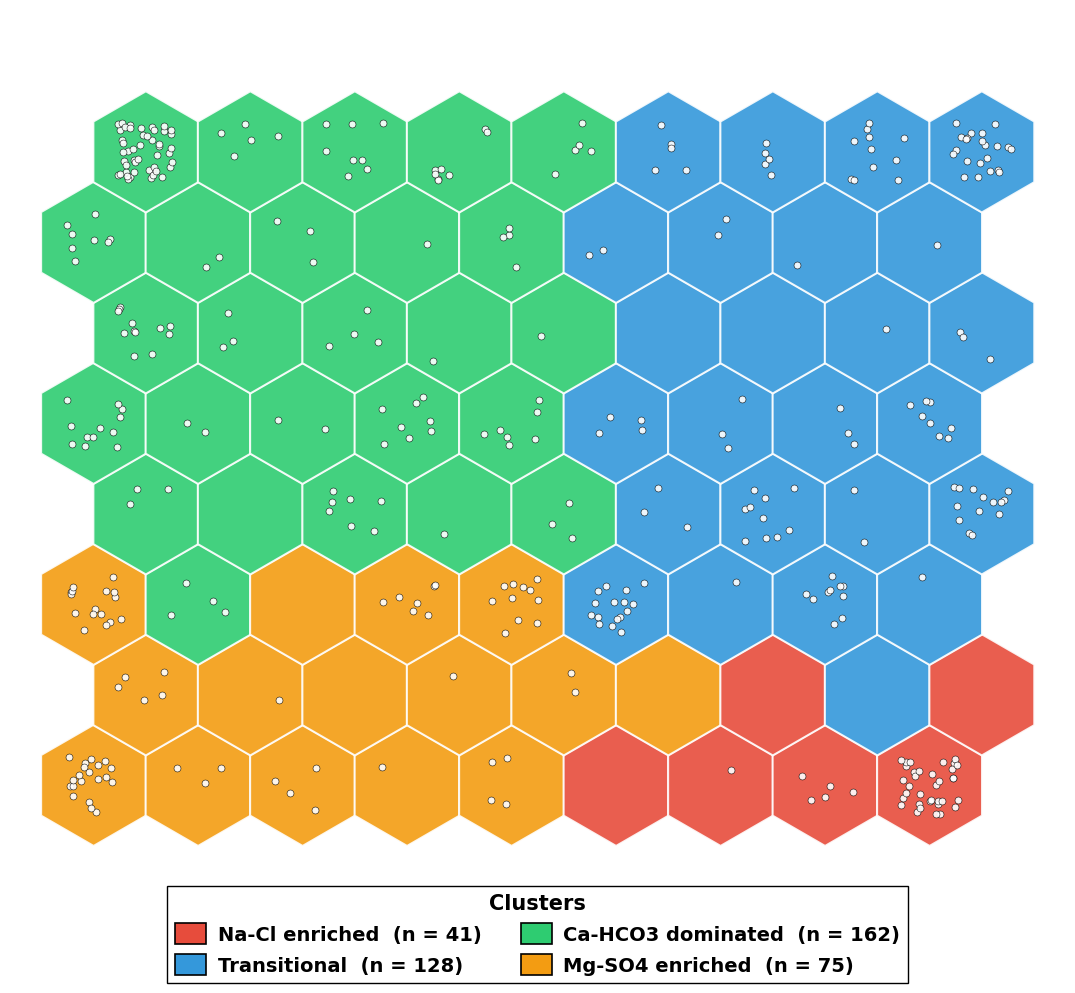

Saved: Figure6_clustered_SOM


In [6]:
# ── Figure 6: clustered SOM map with the article cluster names ──────

fig, ax = plt.subplots(figsize=(11, 10))

# ── Draw hexagonal neurons colored by cluster ────────────────────────
for r in range(ROWS):
    for c in range(COLS):
        x = c + 0.5 * (r % 2)
        y = r * np.sqrt(3) / 2
        cluster = neuron_cluster_map[r, c]
        color = CLUSTER_COLORS.get(cluster, "#CCCCCC")

        hex_patch = RegularPolygon(
            (x, y), numVertices=6, radius=0.58,
            orientation=0, facecolor=color, edgecolor="white",
            linewidth=1.5, alpha=0.9,
        )
        ax.add_patch(hex_patch)

# ── Overlay white circles for sample hits ────────────────────────────
np.random.seed(SEED)
for _, row in df.iterrows():
    r, c = int(row["BMU_row"]), int(row["BMU_col"])
    x = c + 0.5 * (r % 2)
    y = r * np.sqrt(3) / 2
    jitter_x = np.random.uniform(-0.28, 0.28)
    jitter_y = np.random.uniform(-0.28, 0.28)
    ax.plot(x + jitter_x, y + jitter_y, "o",
            color="white", markersize=5, markeredgecolor="black",
            markeredgewidth=0.4, alpha=0.9, zorder=5)

ax.set_xlim(-0.8, COLS + 0.3)
ax.set_ylim(-1.8, ROWS * np.sqrt(3) / 2 + 0.5)
ax.set_aspect("equal")
ax.axis("off")

# ── Legend ───────────────────────────────────────────────────────────
legend_handles = [
    Patch(facecolor=CLUSTER_COLORS[k], edgecolor="black", linewidth=1.2,
          label=f"{CLUSTER_LABELS[k]}  (n = {(df['Cluster']==k).sum()})")
    for k in range(1, K_FINAL + 1)
]
leg = ax.legend(handles=legend_handles, loc="lower center",
                ncol=2, fontsize=14, frameon=True,
                framealpha=1, edgecolor="black", fancybox=False,
                bbox_to_anchor=(0.5, -0.02),
                title="Clusters", title_fontsize=15,
                handlelength=1.6, handleheight=1.3, handletextpad=0.6,
                prop={"weight": "bold", "size": 14})
leg.get_title().set_fontweight("bold")

plt.tight_layout()
fig.savefig(DIR_FIGURES / "Figure6_clustered_SOM.png", dpi=800)
plt.show()
print("Saved: Figure6_clustered_SOM")

### <font color='orange'> **6) Figure 9: Gibbs diagrams colored by SOM cluster** </font>

> Drawn with `scripts/gibbs_som1.py`, adapted from the WQChartPy Gibbs module (GPL-3.0): the upper-right domain is labelled "Evaporation Dominance", and the domain labels are repositioned.

In [7]:
# ── Build Gibbs format DataFrame ─────────────────────────────────────
gibbs_df = pd.DataFrame()

gibbs_df["Sample"] = df["SampleID"]
gibbs_df["Label"]  = df["Cluster"].map(CLUSTER_LABELS)
gibbs_df["Color"]  = df["Cluster"].map(CLUSTER_COLORS)
gibbs_df["Marker"] = df["Type"].map(type_marker_map).fillna("o")
gibbs_df["Size"]   = 30
gibbs_df["Alpha"]  = 0.7

# Ion columns (bare names, mg/L)
gibbs_df["Ca"]   = df["Ca (mg/L)"].values
gibbs_df["Na"]   = df["Na (mg/L)"].values
gibbs_df["HCO3"] = df["HCO3 (mg/L)"].values
gibbs_df["Cl"]   = df["Cl (mg/L)"].values

# TDS = sum of all major ions (mg/L)
gibbs_df["TDS"] = df[MAJOR_IONS].sum(axis=1).values

gibbs_df.reset_index(drop=True, inplace=True)

print(f"Gibbs DataFrame: {gibbs_df.shape}")
print(f"TDS range: {gibbs_df['TDS'].min():.0f} – {gibbs_df['TDS'].max():.0f} mg/L")

Gibbs DataFrame: (406, 11)
TDS range: 5 – 18666 mg/L


Gibbs plot created. Saving it to C:\Users\Admin\OneDrive - Université Mohammed VI Polytechnique\Bureau\Article_Hydrochemistry&Isotopes\haouz-mejjate-recharge-som-emma\notebooks\03_PCA_SOM_HCA 



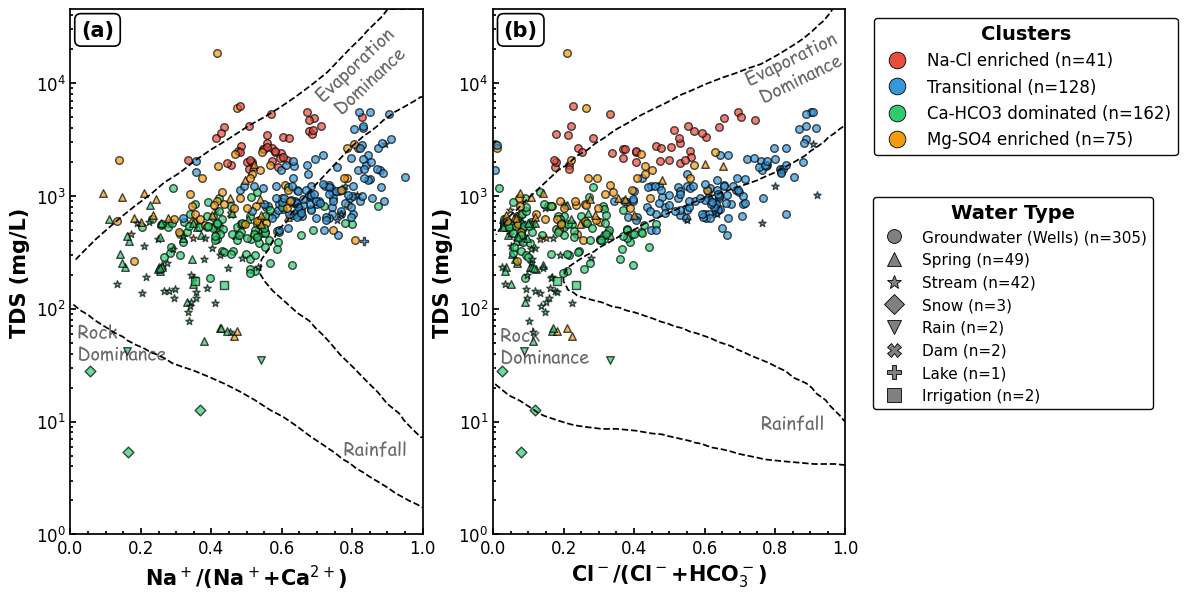

Saved: Figure9_Gibbs_SOM


In [8]:
# ── Figure 9: Gibbs diagrams, legends outside the panels ─────────────

gibbs_figname3 = str(DIR_FIGURES / "Figure9_Gibbs_SOM")

# Plot Gibbs (single call)
gibbs.plot(
    gibbs_df,
    unit="mg/L",
    figname=gibbs_figname3,
    figformat="png",
)

fig = plt.gcf()
all_axes = fig.get_axes()

# Remove ALL default legends from both panels
for ax in all_axes:
    leg = ax.get_legend()
    if leg:
        leg.remove()

# ── Build legend handles ─────────────────────────────────────────────
cluster_handles = [
    Line2D([0], [0], marker="o", color=CLUSTER_COLORS[k], linestyle="None",
           markersize=12, markeredgecolor="black", markeredgewidth=0.6,
           label=f"{CLUSTER_LABELS[k]} (n={(df['Cluster']==k).sum()})")
    for k in range(1, K_FINAL + 1)
]

# Display names for the legend
type_display = {"Groundwater": "Groundwater (Wells)", "Lac": "Lake"}

type_handles = [
    Line2D([0], [0], marker=m, color="gray", linestyle="None",
           markersize=10, markeredgecolor="black", markeredgewidth=0.6,
           label=f"{type_display.get(t, t)} (n={(df['Type']==t).sum()})")
    for t, m in type_marker_map.items() if t in df["Type"].values
]

# ── Both legends to the right of the panels ──────────────────────────
# Cluster legend - top
leg1 = fig.legend(
    handles=cluster_handles,
    loc="upper left",
    bbox_to_anchor=(0.92, 0.88),
    fontsize=12,
    frameon=True, framealpha=0.95, edgecolor="black",
    title="Clusters", title_fontsize=14,
)
leg1.get_title().set_fontweight("bold")

# Type legend - below clusters
leg2 = fig.legend(
    handles=type_handles,
    loc="upper left",
    bbox_to_anchor=(0.92, 0.76),
    fontsize=11,
    frameon=True, framealpha=0.95, edgecolor="black",
    title="Water Type", title_fontsize=14,
)
leg2.get_title().set_fontweight("bold")

# Panel labels (a), (b) - to match the article figure caption
for ax_p, plab in zip(all_axes[:2], ["(a)", "(b)"]):
    ax_p.text(0.03, 0.98, plab, transform=ax_p.transAxes,
              ha="left", va="top", fontsize=15, fontweight="bold",
              bbox=dict(boxstyle="round,pad=0.3", facecolor="white",
                        edgecolor="black", linewidth=1.2), zorder=10)

# Boost axis labels / tick sizes
for ax_g in all_axes:
    if ax_g.get_xlabel():
        ax_g.set_xlabel(ax_g.get_xlabel(), fontsize=15, fontweight="bold")
    if ax_g.get_ylabel():
        ax_g.set_ylabel(ax_g.get_ylabel(), fontsize=15, fontweight="bold")
    ax_g.tick_params(axis="both", labelsize=12)

fig.savefig(gibbs_figname3 + ".png", dpi=800, bbox_inches="tight")
plt.show()

print("Saved: Figure9_Gibbs_SOM")

### <font color='orange'> **7) Figure 7: HCA dendrogram and median Stiff diagrams** </font>

> Independent check of the SOM clusters: Ward-linkage HCA on the 406 standardized samples, phenon line at the distance giving K = 4, branches colored by cluster. The median Stiff diagram of each cluster (meq/L) summarizes its chemical signature. The dendrogram and the four Stiff diagrams are assembled into Figure 7 in the article.

Phenon line distance for K=4: 16


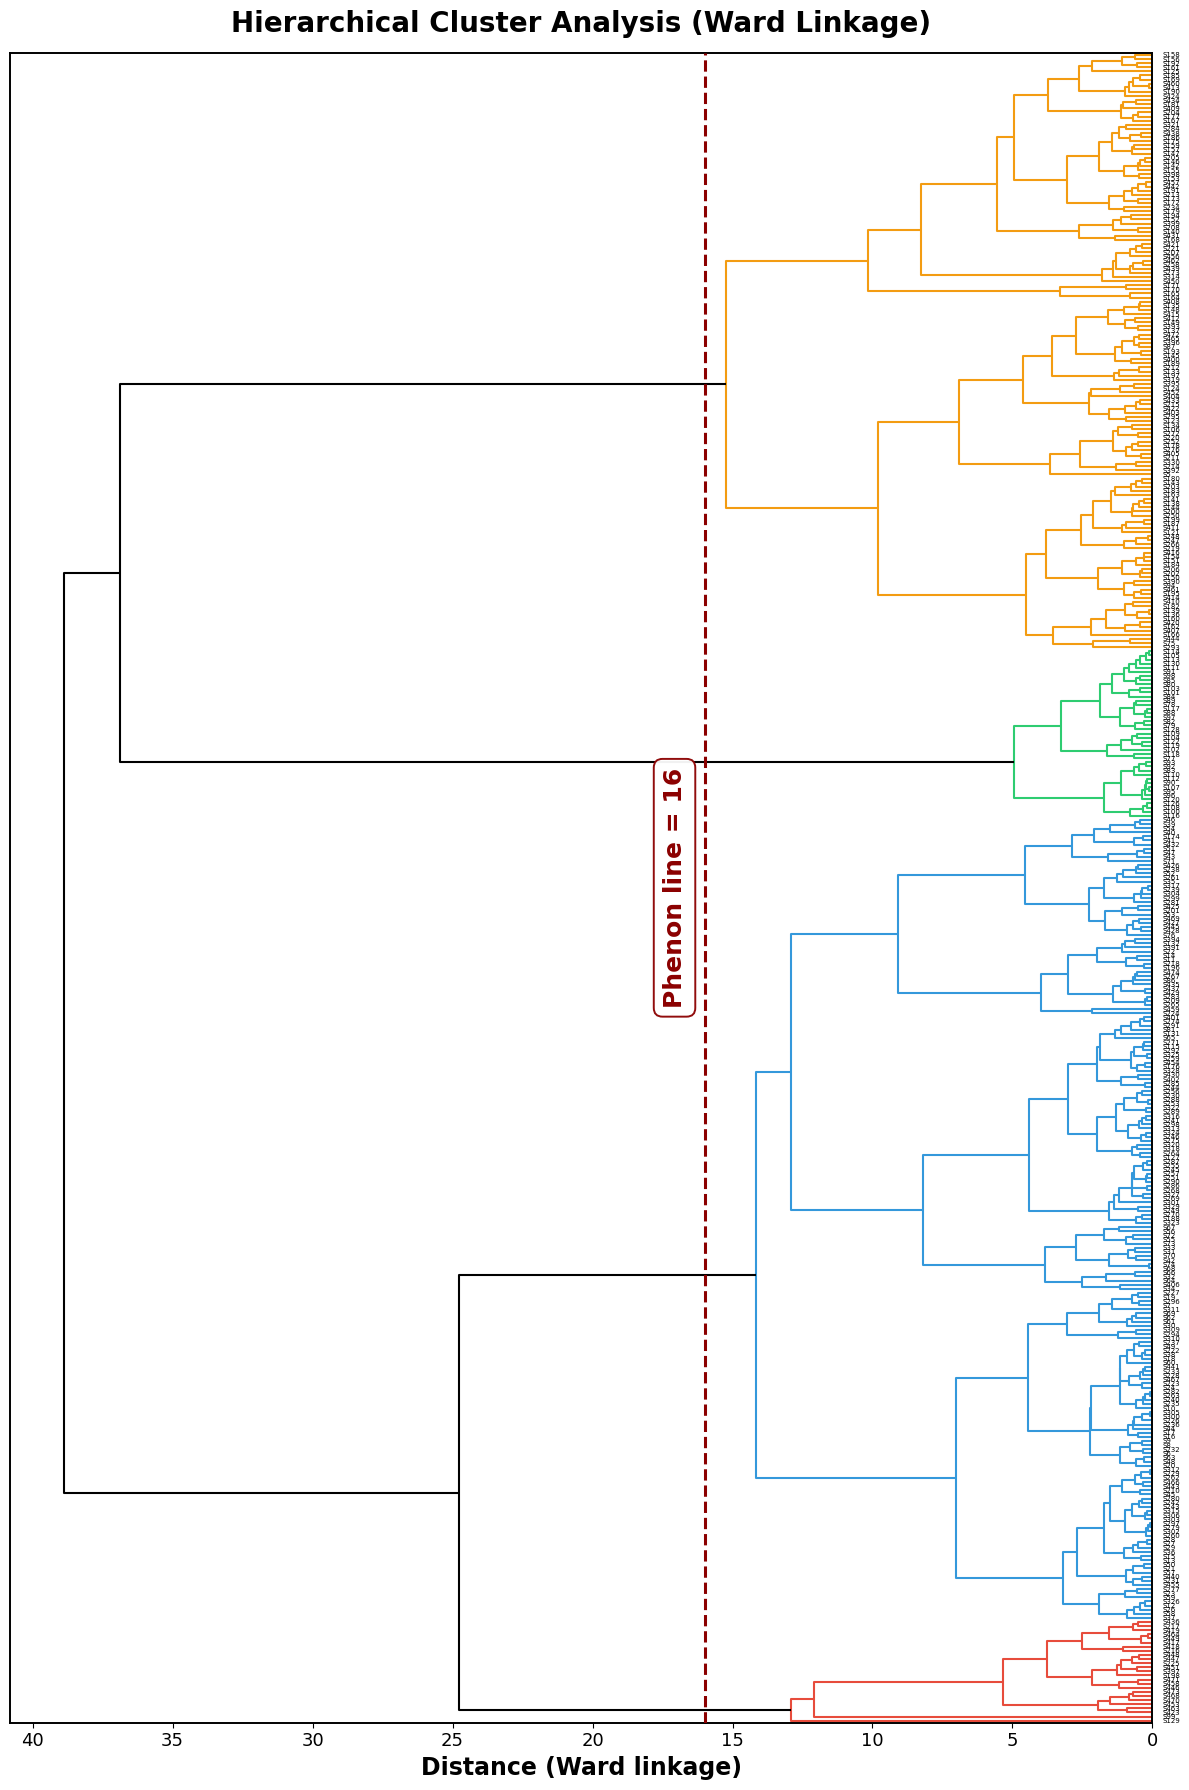


Saved: Figure7_panels/Figure7_HCA_dendrogram


In [9]:
# ── Figure 7 (left): HCA dendrogram - Ward linkage + phenon line ─────

# ── Linkage on standardized data (same input as SOM) ─────────────────
Z_samples = sch.linkage(data_som, method="ward", metric="euclidean")

# ── Find distance threshold for K=4 clusters ────────────────────────
def find_phenon_distance(Z, k, iters=50):
    lo, hi = 0, Z[-1, 2] * 1.001
    for _ in range(iters):
        mid = (lo + hi) / 2
        labels = fcluster(Z, t=mid, criterion="distance")
        n_clusters = len(set(labels))
        if n_clusters > k:
            lo = mid
        else:
            hi = mid
    for candidate in [round(mid), int(mid), int(mid) + 1]:
        if len(set(fcluster(Z, t=candidate, criterion="distance"))) == k:
            return candidate
    return round(mid, 1)

phenon_cut = find_phenon_distance(Z_samples, K_FINAL)
print(f"Phenon line distance for K={K_FINAL}: {phenon_cut}")

# ── Cluster color palette (same as SOM clusters) ────────────────────
PALETTE = [CLUSTER_COLORS[k] for k in range(1, K_FINAL + 1)]

# ── Plot dendrogram (horizontal) ─────────────────────────────────────
# Local rcParams override for the dendrogram (sample labels are dense)
plt.rcParams.update({
    "axes.linewidth": 1.6,
    "xtick.labelsize": 13,
    "ytick.labelsize": 6,
})

fig, ax = plt.subplots(figsize=(12, 18))

sch.set_link_color_palette(PALETTE)
dn = sch.dendrogram(
    Z_samples,
    orientation="left",
    labels=df["SampleID"].values,
    leaf_rotation=0,
    leaf_font_size=5,
    color_threshold=phenon_cut,
    above_threshold_color="black",
    ax=ax,
)
sch.set_link_color_palette(None)

# ── Phenon line ─────────────────────────────────────────────────────
ax.axvline(x=phenon_cut, color="#8B0000", linestyle="--", linewidth=2.2, zorder=10)

# Label offset to the right of the line (not on top)
ax.text(phenon_cut + 1.5, ax.get_ylim()[1] * 0.5,
        f"Phenon line = {phenon_cut}",
        color="#8B0000", fontsize=18, fontweight="bold",
        va="center", ha="left", rotation=90,
        bbox=dict(boxstyle="round,pad=0.35", facecolor="white",
                  edgecolor="#8B0000", linewidth=1.4, alpha=0.95))

ax.set_xlabel("Distance (Ward linkage)", fontsize=17, fontweight="bold")
ax.set_ylabel("")
ax.set_title("Hierarchical Cluster Analysis (Ward Linkage)",
             fontsize=20, fontweight="bold", pad=15)

# Black axes
for spine in ax.spines.values():
    spine.set_edgecolor("black")
    spine.set_linewidth(1.4)

plt.tight_layout()
fig.savefig(DIR_FIG7 / "Figure7_HCA_dendrogram.png", dpi=800)
plt.show()

print("\nSaved: Figure7_panels/Figure7_HCA_dendrogram")

Stiff plot created for C1 median. Saving it to C:\Users\Admin\OneDrive - Université Mohammed VI Polytechnique\Bureau\Article_Hydrochemistry&Isotopes\haouz-mejjate-recharge-som-emma\notebooks\03_PCA_SOM_HCA

  C1 (Na-Cl enriched): median of 41 samples → saved
Stiff plot created for C2 median. Saving it to C:\Users\Admin\OneDrive - Université Mohammed VI Polytechnique\Bureau\Article_Hydrochemistry&Isotopes\haouz-mejjate-recharge-som-emma\notebooks\03_PCA_SOM_HCA

  C2 (Transitional): median of 128 samples → saved
Stiff plot created for C3 median. Saving it to C:\Users\Admin\OneDrive - Université Mohammed VI Polytechnique\Bureau\Article_Hydrochemistry&Isotopes\haouz-mejjate-recharge-som-emma\notebooks\03_PCA_SOM_HCA

  C3 (Ca-HCO3 dominated): median of 162 samples → saved
Stiff plot created for C4 median. Saving it to C:\Users\Admin\OneDrive - Université Mohammed VI Polytechnique\Bureau\Article_Hydrochemistry&Isotopes\haouz-mejjate-recharge-som-emma\notebooks\03_PCA_SOM_HCA

  C4 (Mg-SO4 

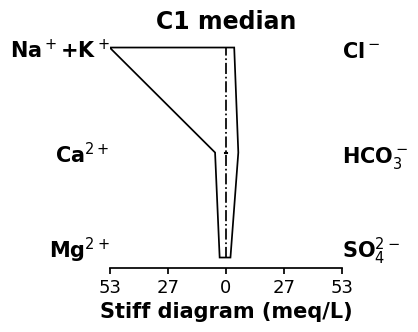

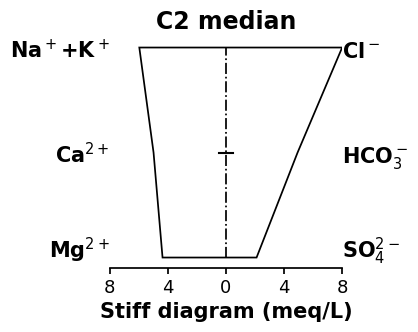

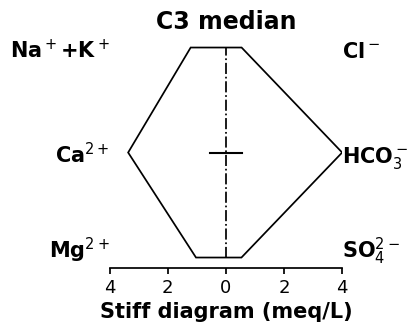

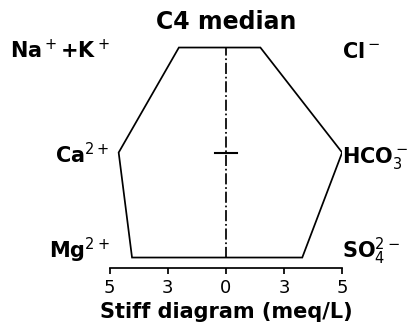

In [10]:
# ── Figure 7 (right): median Stiff diagram per cluster ───────────────

for k in range(1, K_FINAL + 1):
    df_ck = df[df["Cluster"] == k]

    # Compute MEDIAN concentrations for this cluster (one representative sample)
    stiff_df = pd.DataFrame({
        "Sample":  [f"C{k} median"],
        "Label":   [CLUSTER_LABELS[k]],
        "Color":   [CLUSTER_COLORS[k]],
        "Marker":  ["o"],
        "Size":    [20],
        "Alpha":   [0.9],
        "Ca":      [df_ck["Ca (mg/L)"].median()],
        "Mg":      [df_ck["Mg (mg/L)"].median()],
        "Na":      [df_ck["Na (mg/L)"].median()],
        "K":       [df_ck["K (mg/L)"].median()],
        "HCO3":    [df_ck["HCO3 (mg/L)"].median()],
        "Cl":      [df_ck["Cl (mg/L)"].median()],
        "SO4":     [df_ck["SO4 (mg/L)"].median()],
        "CO3":     [0],
    })

    figname = str(DIR_FIG7 / f"Figure7_Stiff_C{k}_{CLUSTER_LABELS[k].replace(' ', '_')}")

    stiff.plot(stiff_df, unit="mg/L", figname=figname, figformat="png")

    # Boost text size on the rendered Stiff figure before exporting PNG
    fig = plt.gcf()
    for ax in fig.get_axes():
        for txt in ax.texts:
            txt.set_fontsize(15)
            txt.set_fontweight("bold")
        if ax.get_title():
            ax.set_title(ax.get_title(), fontsize=17, fontweight="bold")
        if ax.get_xlabel():
            ax.set_xlabel(ax.get_xlabel(), fontsize=15, fontweight="bold")
        if ax.get_ylabel():
            ax.set_ylabel(ax.get_ylabel(), fontsize=15, fontweight="bold")
        ax.tick_params(axis="both", labelsize=13)
    fig.savefig(figname + ".png", dpi=800, bbox_inches="tight")

    print(f"  C{k} ({CLUSTER_LABELS[k]}): median of {len(df_ck)} samples → saved")

print("\n4 Stiff diagrams saved to Figure7_panels/")


# ── Check against the article ────────────────────────────────────────
assert phenon_cut == 16, phenon_cut                      # Figure 7 caption
assert df["Cluster"].value_counts().to_dict() == {1: 41, 2: 128, 3: 162, 4: 75}
print("\n✓ Matches the article: phenon line at distance 16; C1-C4 = 41/128/162/75 samples.")

---
**Figures:** Figure 6, Figure 8, Figure 9 in `outputs/figures/`; Figure 7 panels in `outputs/figures/Figure7_panels/`

**Next:** `04_isotopes/01_isotope_dataset.ipynb`